In [1]:
import hashlib

# 1. Get the username part of your email
username = "ritama.sanyal"

# 2. Generate the saeed using the provided formula
your_seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)

print(f"Your personalized random seed is: {your_seed}")

Your personalized random seed is: 284869898


### Q5.1

In [2]:
import numpy as np

class PCA:
    """
    A custom implementation of Principal Component Analysis (PCA) from scratch.

    This class is used to reduce the dimensionality of data by projecting it onto
    a lower-dimensional space defined by its principal components.

    Parameters
    ----------
    n_components : int
        The number of principal components to keep.

    Attributes
    ----------
    mean_ : np.ndarray
        The mean of each feature in the training data.
    components_ : np.ndarray
        The principal components (eigenvectors of the covariance matrix).
    explained_variance_ratio_ : np.ndarray
        The percentage of variance explained by each of the selected components.
    """

    def __init__(self, n_components):
        """
        Initializes the PCA model.

        Parameters
        ----------
        n_components : int
            The number of principal components to keep.
        """
        if n_components <= 0:
            raise ValueError("n_components must be a positive integer.")
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        """
        Computes the principal components from the training data.

        The fitting process involves centering the data, computing the covariance
        matrix, and then finding its eigenvectors and eigenvalues to determine
        the principal components.

        Parameters
        ----------
        X : np.ndarray of shape (n_samples, n_features)
            The training data to fit the model on.
        """
        # Step 1: Calculate the mean of each feature and center the data.
        # Centering is crucial for PCA to work correctly.
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Step 2: Compute the covariance matrix.
        # `rowvar=False` indicates that columns are features and rows are samples.
        cov_matrix = np.cov(X_centered, rowvar=False)

        # Step 3: Calculate the eigenvalues and eigenvectors of the covariance matrix.
        # Eigenvectors represent the directions of maximum variance (principal components).
        # Eigenvalues represent the magnitude of variance in those directions.
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        
        # Step 4: Sort eigenvalues and corresponding eigenvectors in descending order.
        # This ranks the principal components by their importance.
        sorted_indices = np.argsort(eigenvalues)[::-1]
        sorted_eigenvalues = eigenvalues[sorted_indices]
        sorted_eigenvectors = eigenvectors[:, sorted_indices]
        
        # Step 5: Store the top `n_components` eigenvectors.
        # These form the new feature space.
        self.components_ = sorted_eigenvectors[:, :self.n_components]
        
        # Step 6: Calculate the explained variance ratio for each component.
        # This shows how much information is captured by each principal component.
        total_variance = np.sum(sorted_eigenvalues)
        self.explained_variance_ratio_ = sorted_eigenvalues / total_variance

    def transform(self, X):
        """
        Projects the data onto the principal components to reduce dimensionality.

        Parameters
        ----------
        X : np.ndarray of shape (n_samples, n_features)
            The data to transform.
        
        Returns
        -------
        np.ndarray of shape (n_samples, n_components)
            The transformed data in the lower-dimensional space.
        """
        if self.components_ is None:
            raise RuntimeError("PCA has not been fitted yet. Call fit() first.")
        
        # Center the data using the mean *from the training set*.
        X_centered = X - self.mean_

        # Project the centered data onto the principal components via dot product.
        transformed_data = np.dot(X_centered, self.components_)
        return transformed_data

    def inverse_transform(self, X_transformed):
        """
        Transforms data from the reduced space back to its original space.

        Parameters
        ----------
        X_transformed : np.ndarray of shape (n_samples, n_components)
            The data in the lower-dimensional space.

        Returns
        -------
        np.ndarray of shape (n_samples, n_features)
            The reconstructed data in the original feature space.
        """
        if self.components_ is None:
            raise RuntimeError("PCA has not been fitted yet. Call fit() first.")
        
        # Reverse the projection using the transpose of the components matrix.
        X_reconstructed_centered = np.dot(X_transformed, self.components_.T)
        
        # Add the original mean back to de-center the data.
        X_reconstructed = X_reconstructed_centered + self.mean_
        return X_reconstructed

    def checkPCA(self, X):
        """
        Checks if the class reduces the dimensions appropriately.

        Parameters
        ----------
        X : np.ndarray
            The data to test the transformation on.
        
        Returns
        -------
        bool
            True if the transformation reduces to the correct number of dimensions,
            False otherwise.
        """
        try:
            # Attempt to transform the data.
            transformed_data = self.transform(X)
            
            # Verify that the output has the expected number of features (columns).
            if transformed_data.shape[1] == self.n_components:
                print(f"Check successful: Original shape {X.shape} -> Transformed shape {transformed_data.shape}")
                return True
            else:
                print(f"Check failed: Transformed data has {transformed_data.shape[1]} columns, expected {self.n_components}.")
                return False
        except Exception as e:
            print(f"An error occurred during checkPCA: {e}")
            return False

In [3]:
import numpy as np

# Create some sample data (100 samples, 10 features)
# This data will now be the same every time due to the seed
sample_data = np.random.rand(100, 10)

# Number of dimensions to reduce to
n_components = 3

# 1. Instantiate the PCA class (assuming the class definition from before is available)
my_pca = PCA(n_components=n_components)

# 2. Fit the model to the data to find the principal components
my_pca.fit(sample_data)

# 3. Transform the data to the new, lower-dimensional space
transformed_data = my_pca.transform(sample_data)

# 4. Check if the implementation works as expected
is_working = my_pca.checkPCA(sample_data)

print(f"\nPCA check returned: {is_working}")
print(f"Shape of original data: {sample_data.shape}")
print(f"Shape of transformed data: {transformed_data.shape}")

Check successful: Original shape (100, 10) -> Transformed shape (100, 3)

PCA check returned: True
Shape of original data: (100, 10)
Shape of transformed data: (100, 3)


### Q5.2

In [4]:
import numpy as np
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt
# This line creates the random number generator object 'rng'
rng = np.random.RandomState(your_seed) 

# --- Load MNIST Dataset ---
print("Loading MNIST dataset (28x28)...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X, y = mnist.data, mnist.target.astype(int)

# Normalize pixel values
X = X / 255.0
print("Dataset loaded.\n")

# --- Construct a Balanced Subset ---
print("Constructing balanced subset of 1000 samples...")
n_samples_per_class = 100
n_classes = 10
subset_indices = []

for digit in range(n_classes):
    digit_indices = np.where(y == digit)[0]
    # Now 'rng.choice' will work correctly
    random_indices = rng.choice(digit_indices, n_samples_per_class, replace=False)
    subset_indices.extend(random_indices)

# Create the balanced subset
X_subset = X[subset_indices]
y_subset = y[subset_indices]

print(f"Subset created with shape: {X_subset.shape}")

Loading MNIST dataset (28x28)...
Dataset loaded.

Constructing balanced subset of 1000 samples...
Subset created with shape: (1000, 784)


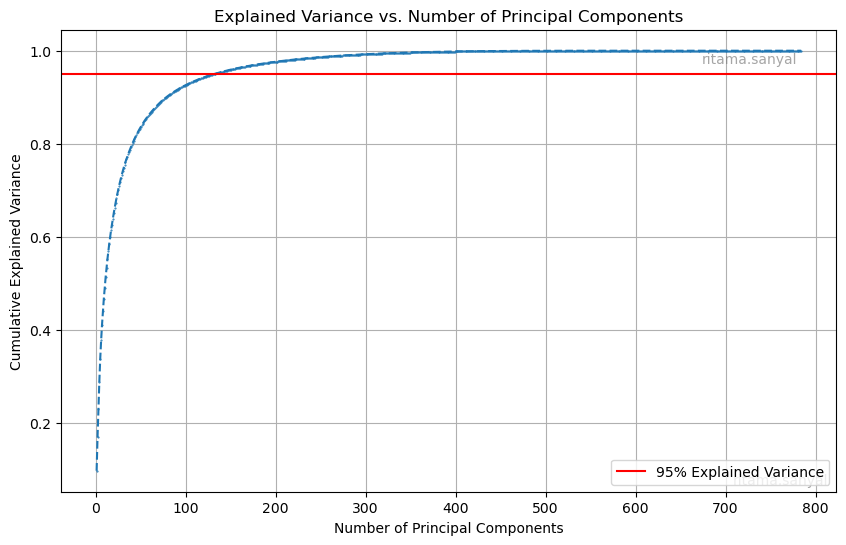

In [5]:
# Fit PCA with all possible components to get the full variance spectrum
pca_full = PCA(n_components=X_subset.shape[1]) # 784 components
pca_full.fit(X_subset)

# Calculate the cumulative explained variance
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='.', linestyle='--', markersize=1)
plt.title('Explained Variance vs. Number of Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.text(0.95, 0.95,"ritama.sanyal", ha='right', va='top',
                 transform=plt.gca().transAxes, fontsize=10, color='gray', alpha=0.7)
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')
plt.legend()
# Add username to plot as per instructions [cite: 25]
plt.text(0.99, 0.01, username, ha='right', va='bottom', transform=plt.gca().transAxes,
         fontsize=10, color='gray', alpha=0.7)
plt.show()

# PCA Explained Variance on MNIST

This plot illustrates how effectively **PCA** can compress the MNIST dataset.  
It addresses the question: **"How much of the original information is preserved if the data is reduced to *X* dimensions?"**

In essence, it visualizes the trade-off between:
- **Simplicity**: using fewer dimensions  
- **Completeness**: retaining as much information as possible  

---

## Key Takeaways

### 1. The Steep Rise
- The curve increases sharply at the beginning.  
- The first ~100 principal components capture approximately **85–90% of the variance**.  
- These components represent the most fundamental patterns and structures across all handwritten digits.

---

### 2. The 95% Threshold
- The red line marks the **95% explained variance**, a standard benchmark for dimensionality reduction.  
- The curve crosses this threshold at around **150 components**.  
- This indicates that the data can be reduced from **784 dimensions to about 150**, while still retaining **95% of the original information**.  
- This represents a substantial compression with minimal loss.

---

### 3. The Plateau
- Beyond approximately 300 components, the curve flattens considerably.  
- Additional components contribute very little new information.  
- These later components often capture **fine details or noise** rather than meaningful structure.

---

## Summary
PCA demonstrates that the MNIST dataset contains significant redundancy:  
- All 784 pixel dimensions are not necessary to describe the digits effectively.  
- A reduced set of about **150 principal components** suffices to represent the images with high fidelity.  
- This dimensionality reduction is highly beneficial for improving computational efficiency in downstream tasks such as classification, without a substantial loss of accuracy.


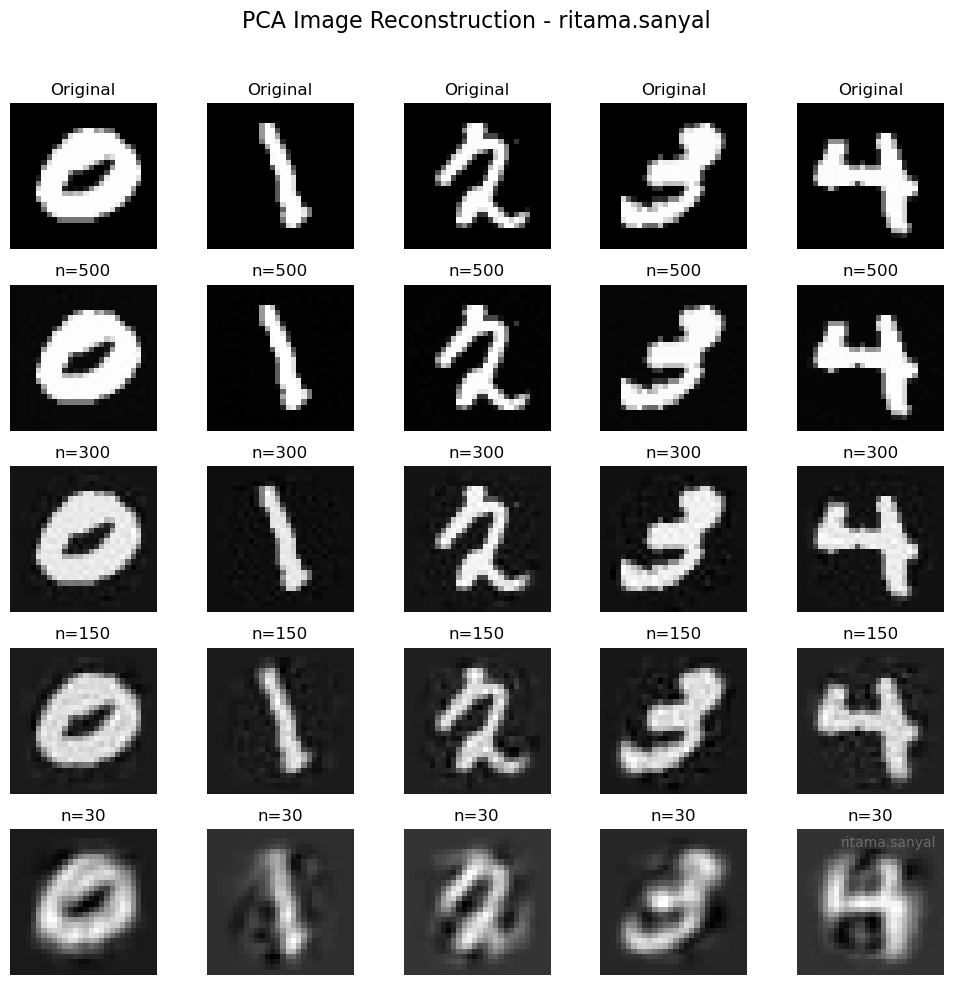

In [6]:
# Target dimensions for reduction
target_dims = [500, 300, 150, 30]

# Select 5 images to visualize
n_images_to_show = 5
indices_to_show = [i * 100 for i in range(n_images_to_show)]
images_to_show = X_subset[indices_to_show]

# Create a figure to display the images
# Rows: 1 for original + one for each target dimension
fig, axes = plt.subplots(len(target_dims) + 1, n_images_to_show, figsize=(10, 10))

# --- Plot Original Images ---
for i in range(n_images_to_show):
    ax = axes[0, i]
    ax.imshow(images_to_show[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"Original")
    ax.axis('off')

# --- Plot Reconstructed Images for each target dimension ---
for row, n_components in enumerate(target_dims, 1):
    # 1. Initialize and fit PCA
    pca = PCA(n_components=n_components)
    pca.fit(X_subset)
    
    # 2. Transform the 5 selected images
    transformed_images = pca.transform(images_to_show)
    
    # 3. Reconstruct the images back to 784 dimensions
    reconstructed_images = pca.inverse_transform(transformed_images)
    
    # 4. Plot the reconstructed images
    for i in range(n_images_to_show):
        ax = axes[row, i]
        ax.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
        ax.set_title(f"n={n_components}")
        ax.axis('off')

fig.suptitle(f'PCA Image Reconstruction - {username}', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.text(0.95, 0.95,"ritama.sanyal", ha='right', va='top',
                 transform=plt.gca().transAxes, fontsize=10, color='gray', alpha=0.7)
plt.show()

# PCA Reconstruction Observations

### High Dimensions (n=500, n=300)
- Reconstructed images are nearly indistinguishable from the originals.  
- A large number of components captures almost all of the variance (information) in the dataset.

### Medium Dimensions (n=150)
- Images are still very clear and easily recognizable.  
- Very slight loss of sharpness, but essential features are preserved.  
- Matches the explained variance plot: ~150 components capture about **95% of the information**.

### Low Dimensions (n=30)
- Significant quality loss.  
- Images become much blurrier, losing fine details.  
- General digit shape is visible, but distinguishing details (e.g., the loop in a *9* or the opening in a *4*) are distorted.  
- Demonstrates that 30 components are not sufficient to capture the full complexity of handwritten digits.

---

## Summary
There is a **trade-off between the number of dimensions and reconstruction quality**:
- Fewer dimensions → Saves computational resources, but loses information.  
- More dimensions → Preserves detail, but increases computational cost.  
- Blurriness in reconstructed images is a direct manifestation of information loss.


https://g.co/gemini/share/538601185142